<a href="https://colab.research.google.com/github/RiyaMahajan4/fraudshield-ai/blob/main/notebooks/02_exploratory_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exploratory Data Analysis — FraudShield AI
Objective

This notebook explores the credit card transaction dataset to understand its structure, investigate class imbalance, compare legitimate and fraudulent transactions, and identify patterns that may be useful for machine learning.

Key Questions
1. How imbalanced is the dataset?
2. How do transaction amounts differ between legitimate and fraudulent transactions?
3. Are there differences in transaction timing?
4. Which anonymized features show differences between the two classes?
5. What data-quality or modeling concerns should be addressed before training?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("/content/creditcard.csv")

# Verify the dataset
print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())

df.head()

Dataset shape: (284807, 31)
Missing values: 0


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [2]:
# Count transactions in each class
class_counts = df["Class"].value_counts().sort_index()

# Calculate percentages
class_percentages = (
    df["Class"].value_counts(normalize=True).sort_index() * 100
)

print("Transaction counts:")
print(class_counts)

print("\nTransaction percentages:")
print(class_percentages.round(4))

Transaction counts:
Class
0    284315
1       492
Name: count, dtype: int64

Transaction percentages:
Class
0    99.8273
1     0.1727
Name: proportion, dtype: float64


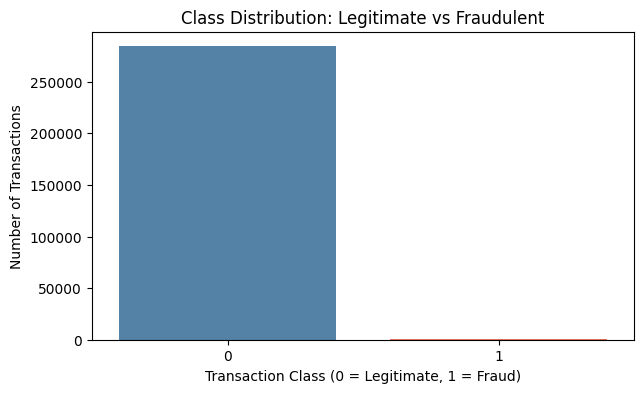

In [3]:
plt.figure(figsize=(7, 4))

sns.countplot(
    data=df,
    x="Class",
    hue="Class",
    palette=["steelblue", "tomato"],
    legend=False
)

plt.title("Class Distribution: Legitimate vs Fraudulent")
plt.xlabel("Transaction Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")

plt.show()

### Observation — Class Imbalance

The dataset is highly imbalanced, with fraudulent transactions representing approximately 0.173% of all observations.

A classifier that always predicts the majority class would achieve approximately 99.83% accuracy while detecting no fraud.

Therefore, accuracy alone will not be sufficient for model evaluation. Precision, recall, F1-score, and particularly PR-AUC will be important evaluation metrics.

Class imbalance will also need to be considered when selecting training strategies and decision thresholds.

#2. Transaction Amount Analysis
Objective

To compare the transaction amount distributions of legitimate and fraudulent transactions and identify potential differences relevant to fraud detection.

**Hypothesis:** Fraudulent transactions may have different transaction amount patterns compared with legitimate transactions.

In [4]:
# Compare transaction amounts by class

amount_stats = df.groupby("Class")["Amount"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

print("Transaction Amount Statistics:")
display(amount_stats.round(2))

Transaction Amount Statistics:


,count,mean,median,std,min,max
Class,,,,,,
0,284315,88.29,22.00,250.11,0.0,25691.16
1,492,122.21,9.25,256.68,0.0,2125.87


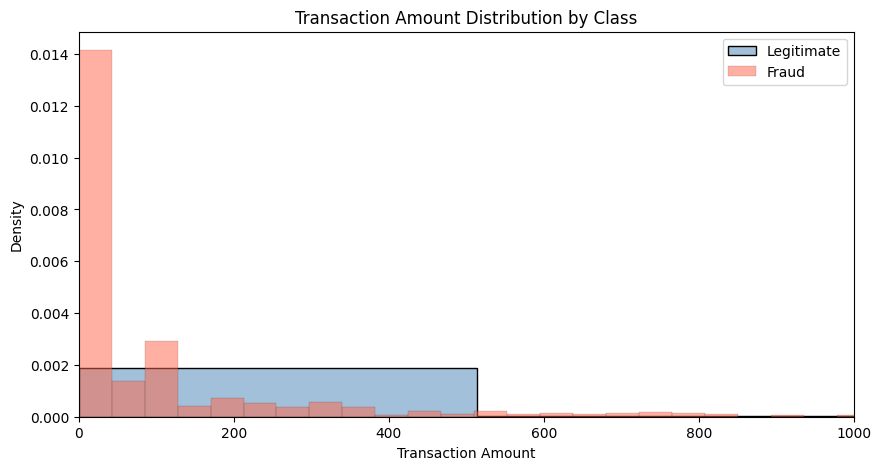

In [5]:
# Separate legitimate and fraudulent transactions
legitimate = df[df["Class"] == 0]
fraud = df[df["Class"] == 1]

plt.figure(figsize=(10, 5))

sns.histplot(
    legitimate["Amount"],
    bins=50,
    color="steelblue",
    alpha=0.5,
    stat="density",
    label="Legitimate"
)

sns.histplot(
    fraud["Amount"],
    bins=50,
    color="tomato",
    alpha=0.5,
    stat="density",
    label="Fraud"
)

plt.xlim(0, 1000)
plt.title("Transaction Amount Distribution by Class")
plt.xlabel("Transaction Amount")
plt.ylabel("Density")
plt.legend()
plt.show()

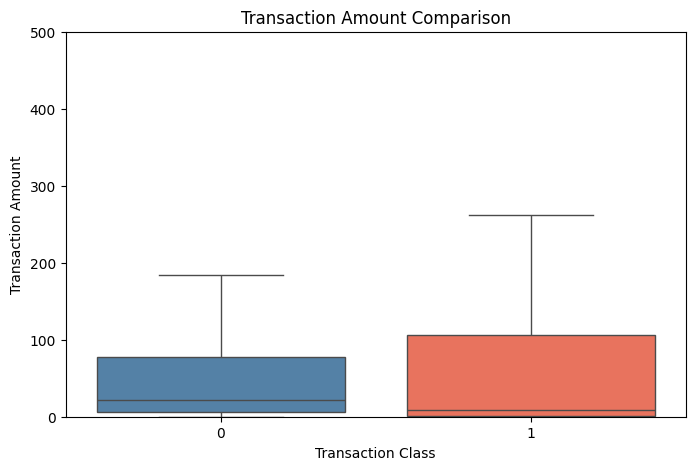

In [6]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Class",
    y="Amount",
    hue="Class",
    palette=["steelblue", "tomato"],
    legend=False,
    showfliers=False
)

plt.title("Transaction Amount Comparison")
plt.xlabel("Transaction Class")
plt.ylabel("Transaction Amount")
plt.ylim(0, 500)

plt.show()

In [7]:
print("Average transaction amounts:")

print("Legitimate:",
      df[df["Class"] == 0]["Amount"].mean())

print("Fraud:",
      df[df["Class"] == 1]["Amount"].mean())

Average transaction amounts:
Legitimate: 88.29102242231328
Fraud: 122.21132113821139


### Final Observations — Transaction Amount Analysis

The average fraudulent transaction amount (122.21) is higher than the average legitimate transaction amount (88.29).

However, the boxplot indicates that the median fraudulent transaction amount is lower than the median legitimate transaction amount.

This difference suggests that the transaction amount distribution is skewed, with larger transactions influencing the mean.

Both classes contain transactions across overlapping amount ranges, indicating that transaction amount alone is insufficient for reliable fraud classification.

**ML Implication:** Transaction amount may contribute useful information, but the model must learn patterns across multiple features.

In [9]:
# Convert elapsed seconds into hours
df["Time_Hours"] = df["Time"] / 3600

# Compare transaction timing by class
time_stats = df.groupby("Class")["Time_Hours"].agg(
    ["mean", "median", "min", "max"]
)

display(time_stats.round(2))

,mean,median,min,max
Class,,,,
0,26.34,23.53,0.00,48.00
1,22.43,20.99,0.11,47.32


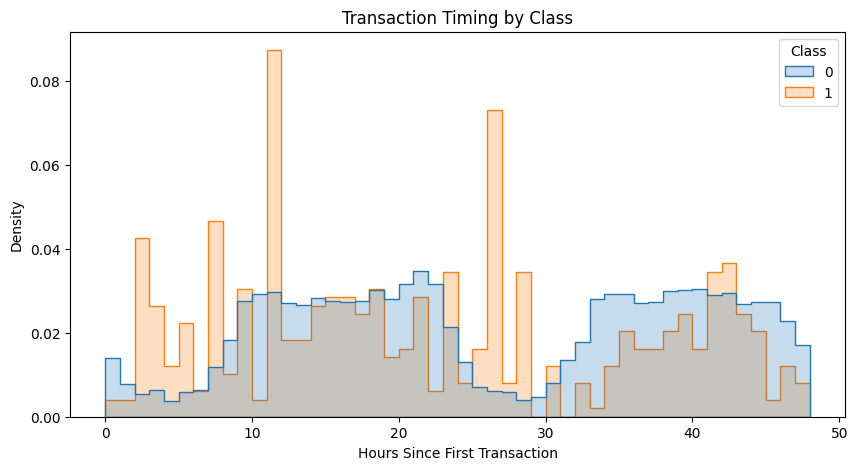

In [10]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Time_Hours",
    hue="Class",
    bins=48,
    stat="density",
    common_norm=False,
    element="step"
)

plt.title("Transaction Timing by Class")
plt.xlabel("Hours Since First Transaction")
plt.ylabel("Density")

plt.show()

### Observations — Transaction Time Analysis

1. Legitimate transactions exhibit varying activity levels across the approximately 48-hour observation period.

2. Fraudulent transactions appear more unevenly distributed, with several noticeable peaks in their density.

3. Both legitimate and fraudulent transactions occur across overlapping time intervals.

4. Transaction timing alone does not appear sufficient to distinguish fraudulent transactions reliably.

**ML Implication:** The `Time` feature may provide useful predictive information when combined with other transaction characteristics. However, further modeling is required to determine its actual contribution.

**Limitation:** The dataset covers approximately two days, and the `Time` feature represents elapsed seconds rather than actual clock time. Therefore, the graph cannot establish long-term or daily fraud patterns.

## 4. Anonymized Feature Analysis
 Objective

To investigate statistical relationships between the anonymized PCA features (V1–V28) and fraudulent transactions.

This analysis aims to identify potentially informative features for further investigation during model development.

In [11]:
# Select the anonymized features
feature_cols = [f"V{i}" for i in range(1, 29)]

# Calculate correlations with the target
correlations = df[feature_cols + ["Class"]].corr()["Class"]

# Remove the target's correlation with itself
correlations = correlations.drop("Class")

# Sort by absolute correlation strength
correlations = correlations.reindex(
    correlations.abs().sort_values(ascending=False).index
)

# Display the top 10
print("Top 10 features correlated with fraud:")
display(correlations.head(10).round(4))

Top 10 features correlated with fraud:


,Class
V17,-0.3265
V14,-0.3025
V12,-0.2606
V10,-0.2169
V16,-0.1965
V3,-0.1930
V7,-0.1873
V11,0.1549
V4,0.1334
V18,-0.1115


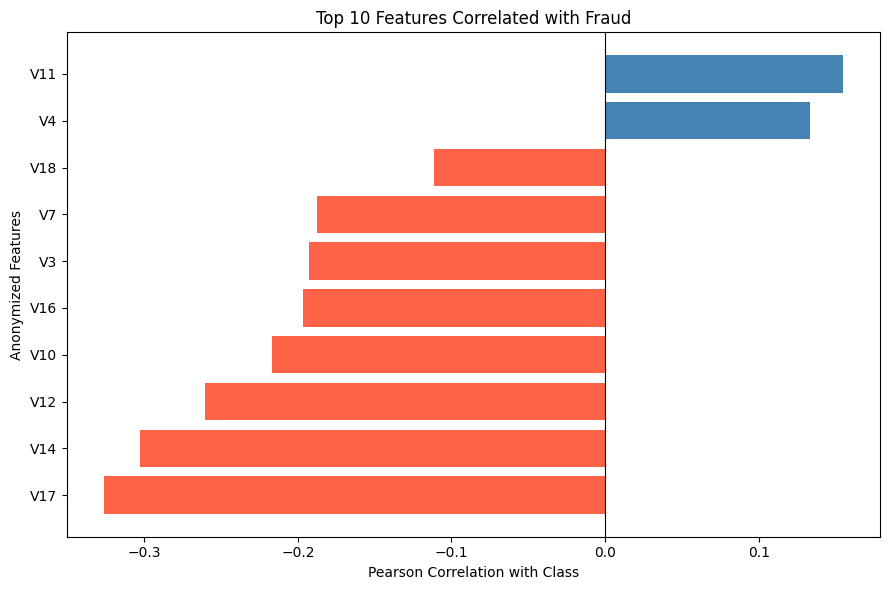

In [12]:
# Plot top 10 features correlated with fraud
top_10 = correlations.head(10).sort_values()

plt.figure(figsize=(9, 6))

colors = [
    "tomato" if value < 0 else "steelblue"
    for value in top_10.values
]

plt.barh(
    top_10.index,
    top_10.values,
    color=colors
)

plt.axvline(0, color="black", linewidth=0.8)

plt.title("Top 10 Features Correlated with Fraud")
plt.xlabel("Pearson Correlation with Class")
plt.ylabel("Anonymized Features")

plt.tight_layout()
plt.show()

### Observations — Feature Correlation Analysis

The Pearson correlation analysis identified V17, V14, and V12 as the anonymized features with the strongest absolute linear associations with the fraud label.

Most of the top-ranked features exhibit negative correlations, suggesting that lower values tend to be associated with fraudulent transactions. V11 and V4 show positive correlations.

However, correlation does not establish causation or guarantee predictive importance. Features with weak individual correlations may still contribute to nonlinear machine learning models.

**ML Implication:** These findings provide an initial understanding of feature relationships. All available features will be considered during baseline modeling, and feature importance will be investigated using appropriate model evaluation and explainability techniques.

**Methodological note:** These correlations were calculated on the full dataset for exploratory purposes. Model selection and any feature selection will be conducted using training data only, with an untouched test set reserved for final evaluation.

## 5. EDA Summary

 Key Findings
- **Class imbalance:** Only 0.173% of transactions are fraudulent.
- **Transaction amount:** Fraudulent transactions have a higher mean (122.21) but a lower median than legitimate transactions.
- **Transaction timing:** Both classes overlap considerably, although fraud observations show uneven peaks.
- **Feature correlation:** V17, V14, and V12 show the strongest absolute linear associations with fraud.

ML Implications
- Use stratified data splitting and leakage-safe preprocessing.
- Prioritize PR-AUC, precision, recall, and F1-score over accuracy.
- Compare multiple classifiers and optimize decision thresholds using validation data.
- Investigate feature contributions and anomaly detection.

 Conclusion
The dataset presents a highly imbalanced classification problem. Effective fraud detection will require careful evaluation, appropriate preprocessing, and model comparison.